In [1]:
from pathlib import Path
import yaml

PROJECT_ROOT = Path.cwd()
DATASET_DIR = PROJECT_ROOT / "data"

with open(DATASET_DIR / "data.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

print(f"Dataset root: {DATASET_DIR}")
print(f"Classes: {config.get('names')}")
print(f"Train images: {len(list((DATASET_DIR / 'train' / 'images').glob('*')))}")
print(f"Train labels: {len(list((DATASET_DIR / 'train' / 'labels').glob('*.txt')))}")


Dataset root: d:\Projects\cv_project\data
Classes: ['void_detection - v1 2025-04-06 7-16pm']
Train images: 506
Train labels: 506


In [2]:
from PIL import Image

sample_image = next((DATASET_DIR / "train" / "images").glob("*"))
sample_label = next((DATASET_DIR / "train" / "labels").glob("*.txt"))

print('Sample image:', sample_image)
print('Sample label:', sample_label)

with Image.open(sample_image) as img:
    print('Image size:', img.size)


Sample image: d:\Projects\cv_project\data\train\images\IMG-20250318-WA0009_jpg.rf.3c7d769531baff15cf4672028a2fecfa.jpg
Sample label: d:\Projects\cv_project\data\train\labels\IMG-20250318-WA0009_jpg.rf.3c7d769531baff15cf4672028a2fecfa.txt
Image size: (640, 640)


DATASET OVERVIEW
Dataset directory: D:\Projects\cv_project\data
Classes: {0: 'void_detection - v1 2025-04-06 7-16pm'}
Images: 536
Valid parsed annotations: 2490
Issues detected: 0

Images by split:


,Images,Readable,Total_size_MB,Mean_width,Mean_height
Split,,,,,
Test,11,11,0.86,640.0,640.0
Train,506,506,40.03,640.0,640.0
Validation,19,19,1.60,640.0,640.0



Image formats:


,Count
Format,
.jpg,536



Image dimensions:


...

,Count
Format,
Bounding box,2490



Annotations per image, including images with zero valid annotations:


,Images,Total_annotations,Mean,Median,Maximum
Split,,,,,
Test,11,64,5.82,6.0,13
Train,506,2342,4.63,4.0,19
Validation,19,84,4.42,4.0,9



Bounding-box and polygon geometry:


Box width fraction                  \
                                                   count    mean     std   
Class                                                                      
void_detection - v1 2025-04-06 7-16pm             2490.0  0.1494  0.1339   

                                                                               \
                                          min     25%     50%     75%     max   
Class                                                                           
void_detection - v1 2025-04-06 7-16pm  0.0062  0.0688  0.1062  0.1762  0.9688   

                                      Box height fraction         ...  \
                                                    count   mean  ...   
Class                                                             ...   
void_detection - v1 2025-04-06 7-16pm              2490.0  0.105  ...   

                                      Polygon area fraction         Vertices  \
                                                        75%     max    count   
Class                                                                          
void_detection - v1 2025-04-06 7-16pm                0.0194  0.2962   2490.0   

                                                                          
                                      mean  std  min  25%  50%  75%  max  
Class                                                                     
void_detection - v1 2025-04-06 7-16pm  4.0  0.0  4.0  4.0  4.0  4.0  4.0  

[1 rows x 40 columns]

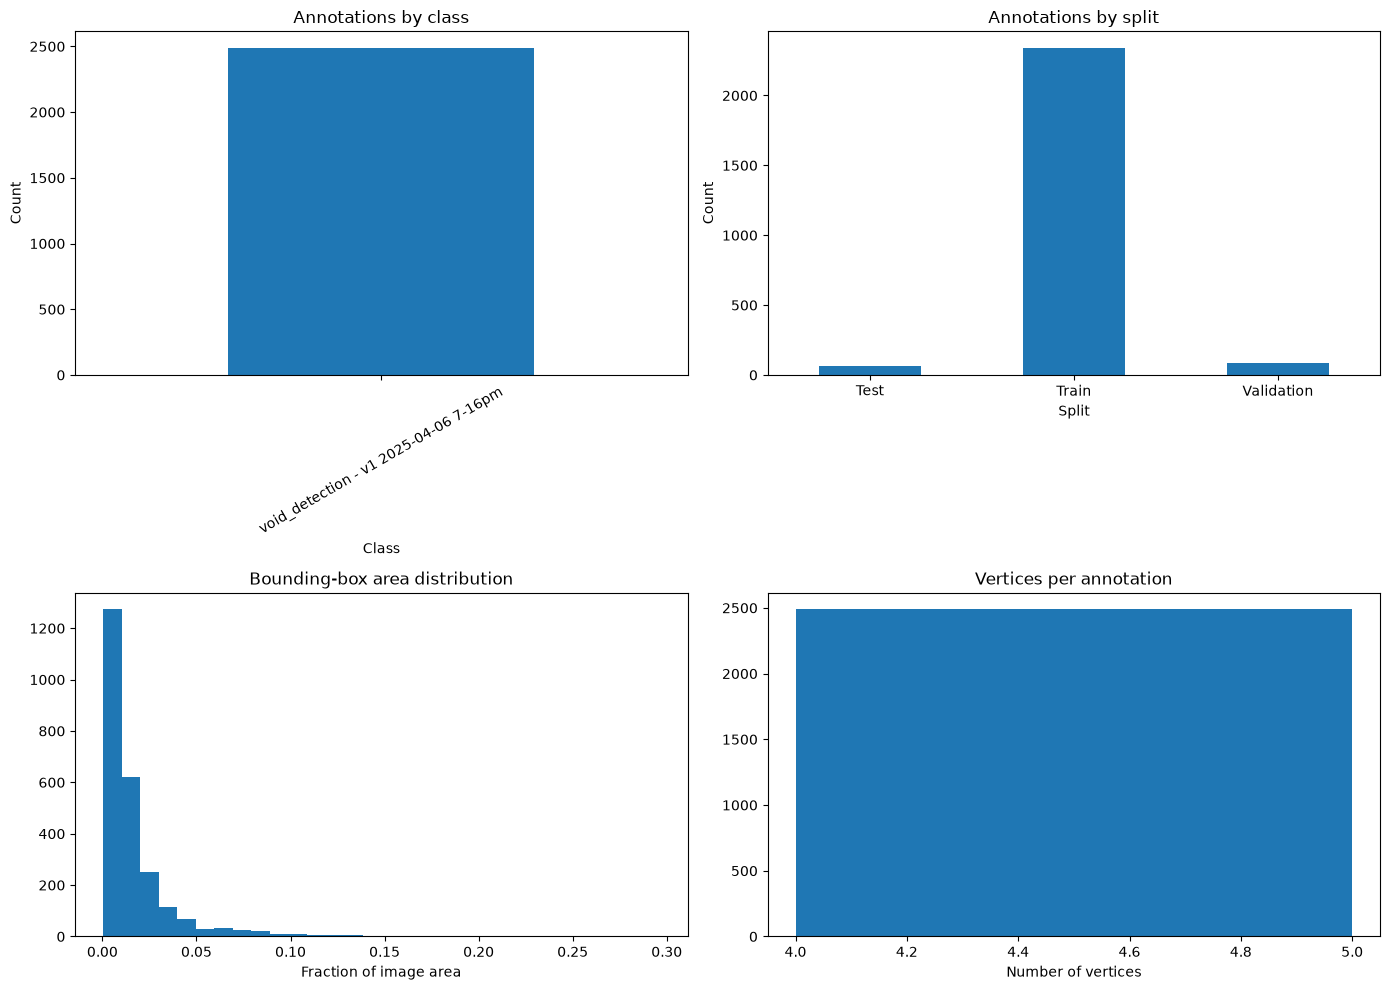

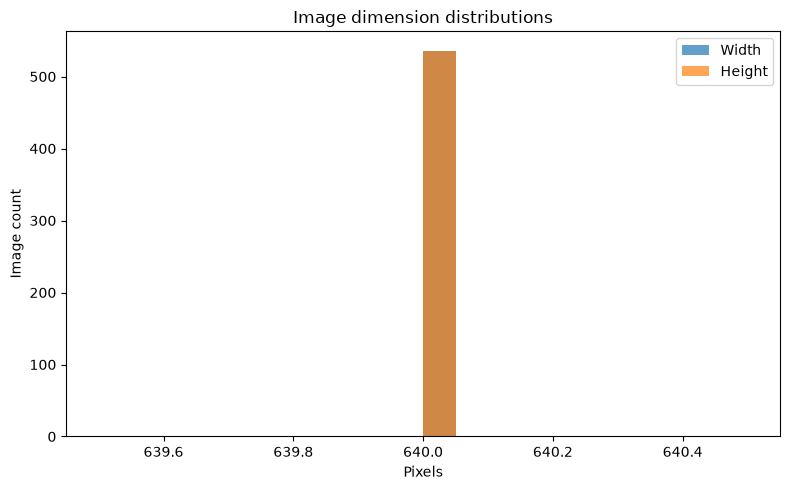


DATA QUALITY ISSUES
Total issues: 0
No issues detected by these checks.

EDA complete. No dataset files were modified.


In [3]:

from pathlib import Path
from collections import Counter, defaultdict
import math
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

# ============================================================
# 1. CONFIGURATION
# ============================================================

DATASET_DIR = Path(DATASET_DIR).resolve()

with open(DATASET_DIR / "data.yaml", "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

names = config.get("names", [])
if isinstance(names, dict):
    class_names = {int(k): str(v) for k, v in names.items()}
else:
    class_names = {i: str(v) for i, v in enumerate(names)}

splits = {
    "Train": DATASET_DIR / "train",
    "Validation": DATASET_DIR / "valid",
    "Test": DATASET_DIR / "test",
}

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_rows = []
annotation_rows = []
issues = []
duplicate_hashes = defaultdict(list)

# ============================================================
# 2. IMAGE AND LABEL AUDIT
# ============================================================

for split_name, split_dir in splits.items():
    image_dir = split_dir / "images"
    label_dir = split_dir / "labels"

    images = sorted(
        p for p in image_dir.glob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    ) if image_dir.exists() else []

    labels = {
        p.stem: p for p in label_dir.glob("*.txt")
    } if label_dir.exists() else {}

    image_stems = {p.stem for p in images}

    if not image_dir.exists():
        issues.append({
            "Split": split_name, "File": str(image_dir),
            "Issue": "Missing image directory"
        })

    if not label_dir.exists():
        issues.append({
            "Split": split_name, "File": str(label_dir),
            "Issue": "Missing label directory"
        })

    for stem in sorted(image_stems - labels.keys()):
        issues.append({
            "Split": split_name, "File": stem,
            "Issue": "Image has no label file"
        })

    for stem in sorted(labels.keys() - image_stems):
        issues.append({
            "Split": split_name, "File": stem,
            "Issue": "Label has no image"
        })

    for image_path in images:
        record = {
            "Split": split_name,
            "Image": image_path.name,
            "Path": str(image_path),
            "Width": np.nan,
            "Height": np.nan,
            "Format": image_path.suffix.lower(),
            "File size (MB)": image_path.stat().st_size / (1024**2),
            "Aspect ratio": np.nan,
            "Readable": False,
        }

        try:
            with Image.open(image_path) as img:
                img.verify()

            with Image.open(image_path) as img:
                width, height = img.size
                record.update({
                    "Width": width,
                    "Height": height,
                    "Aspect ratio": width / height if height else np.nan,
                    "Readable": True,
                })

        except Exception as exc:
            issues.append({
                "Split": split_name, "File": image_path.name,
                "Issue": f"Unreadable image: {exc}"
            })

        image_rows.append(record)

        label_path = labels.get(image_path.stem)
        if label_path is None:
            continue

        lines = label_path.read_text(
            encoding="utf-8"
        ).splitlines()

        if not any(line.strip() for line in lines):
            issues.append({
                "Split": split_name, "File": label_path.name,
                "Issue": "Empty label file"
            })

        for line_number, line in enumerate(lines, start=1):
            if not line.strip():
                continue

            parts = line.split()

            try:
                values = [float(x) for x in parts]
                if not values or not values[0].is_integer():
                    raise ValueError("Invalid class ID")

                class_id = int(values[0])
                coords = values[1:]

                if class_id not in class_names:
                    raise ValueError(f"Unknown class ID {class_id}")

                is_box = len(coords) == 4
                is_polygon = len(coords) >= 6 and len(coords) % 2 == 0

                if not (is_box or is_polygon):
                    raise ValueError(
                        f"Unexpected coordinate count: {len(coords)}"
                    )

                if not all(math.isfinite(v) for v in coords):
                    raise ValueError("Non-finite coordinate")

                if not all(0 <= v <= 1 for v in coords):
                    raise ValueError("Coordinate outside [0, 1]")

                if is_box:
                    xc, yc, bw, bh = coords
                    if bw <= 0 or bh <= 0:
                        raise ValueError("Non-positive box dimensions")

                    x1, x2 = xc - bw / 2, xc + bw / 2
                    y1, y2 = yc - bh / 2, yc + bh / 2

                    if x1 < -1e-6 or x2 > 1 + 1e-6:
                        raise ValueError("Bounding box extends beyond image")
                    if y1 < -1e-6 or y2 > 1 + 1e-6:
                        raise ValueError("Bounding box extends beyond image")

                    polygon_area = bw * bh
                    vertices = 4

                else:
                    points = np.asarray(coords).reshape(-1, 2)
                    vertices = len(points)

                    x, y = points[:, 0], points[:, 1]
                    polygon_area = abs(
                        np.dot(x, np.roll(y, 1))
                        - np.dot(y, np.roll(x, 1))
                    ) / 2

                    bw = float(x.max() - x.min())
                    bh = float(y.max() - y.min())

                    if bw <= 0 or bh <= 0 or polygon_area <= 1e-12:
                        raise ValueError("Degenerate polygon")

                annotation_rows.append({
                    "Split": split_name,
                    "Image": image_path.name,
                    "Class ID": class_id,
                    "Class": class_names[class_id],
                    "Format": "Bounding box" if is_box else "Polygon",
                    "Vertices": vertices,
                    "Box width fraction": bw,
                    "Box height fraction": bh,
                    "Box area fraction": bw * bh,
                    "Polygon area fraction": polygon_area,
                })

            except (ValueError, OverflowError) as exc:
                issues.append({
                    "Split": split_name,
                    "File": label_path.name,
                    "Issue": f"Line {line_number}: {exc}"
                })

# ============================================================
# 3. DATAFRAMES AND OVERALL STATISTICS
# ============================================================

images_df = pd.DataFrame(image_rows)
annotations_df = pd.DataFrame(annotation_rows)
issues_df = pd.DataFrame(issues)

print("=" * 65)
print("DATASET OVERVIEW")
print("=" * 65)
print("Dataset directory:", DATASET_DIR)
print("Classes:", class_names)
print("Images:", len(images_df))
print("Valid parsed annotations:", len(annotations_df))
print("Issues detected:", len(issues_df))

if not images_df.empty:
    print("\nImages by split:")
    display(
        images_df.groupby("Split").agg(
            Images=("Image", "count"),
            Readable=("Readable", "sum"),
            Total_size_MB=("File size (MB)", "sum"),
            Mean_width=("Width", "mean"),
            Mean_height=("Height", "mean"),
        ).round(2)
    )

    print("\nImage formats:")
    display(images_df["Format"].value_counts().to_frame("Count"))

    print("\nImage dimensions:")
    display(
        images_df.groupby(["Width", "Height"], dropna=False)
        .size().reset_index(name="Images")
        .sort_values("Images", ascending=False)
        .head(20)
    )

# ============================================================
# 4. CLASS AND ANNOTATION STATISTICS
# ============================================================

if not annotations_df.empty:
    print("\nAnnotations by class and split:")
    class_table = pd.crosstab(
        annotations_df["Class"], annotations_df["Split"]
    )
    display(class_table)

    print("\nClass shares:")
    class_totals = annotations_df["Class"].value_counts()
    class_report = pd.DataFrame({
        "Annotations": class_totals,
        "Share (%)": 100 * class_totals / class_totals.sum(),
    })
    display(class_report)

    print("\nAnnotation format counts:")
    display(
        annotations_df["Format"].value_counts().to_frame("Count")
    )

    print("\nAnnotations per image, including images with zero valid annotations:")
    if not images_df.empty:
        per_image = images_df[
            ["Split", "Image"]
        ].merge(
            annotations_df.groupby(["Split", "Image"]).size()
            .rename("Annotations").reset_index(),
            on=["Split", "Image"],
            how="left",
        )
        per_image["Annotations"] = (
            per_image["Annotations"].fillna(0).astype(int)
        )
        display(
            per_image.groupby("Split")["Annotations"].agg(
                Images="size",
                Total_annotations="sum",
                Mean="mean",
                Median="median",
                Maximum="max",
            ).round(2)
        )

    print("\nBounding-box and polygon geometry:")
    display(
        annotations_df.groupby("Class")[
            ["Box width fraction", "Box height fraction",
             "Box area fraction", "Polygon area fraction", "Vertices"]
        ].describe().round(4)
    )

# ============================================================
# 5. VISUALIZATIONS
# ============================================================

if not annotations_df.empty:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    annotations_df.groupby("Class").size().plot(
        kind="bar", ax=axes[0, 0], title="Annotations by class"
    )
    axes[0, 0].set_ylabel("Count")
    axes[0, 0].tick_params(axis="x", rotation=30)

    annotations_df.groupby("Split").size().plot(
        kind="bar", ax=axes[0, 1], title="Annotations by split"
    )
    axes[0, 1].set_ylabel("Count")
    axes[0, 1].tick_params(axis="x", rotation=0)

    axes[1, 0].hist(
        annotations_df["Box area fraction"].dropna(),
        bins=30
    )
    axes[1, 0].set_title("Bounding-box area distribution")
    axes[1, 0].set_xlabel("Fraction of image area")

    axes[1, 1].hist(
        annotations_df["Vertices"].dropna(),
        bins=range(
            int(annotations_df["Vertices"].min()),
            int(annotations_df["Vertices"].max()) + 2
        )
    )
    axes[1, 1].set_title("Vertices per annotation")
    axes[1, 1].set_xlabel("Number of vertices")

    plt.tight_layout()
    plt.show()

if not images_df.empty:
    plt.figure(figsize=(8, 5))
    plt.hist(images_df["Width"].dropna(), bins=20, alpha=0.7, label="Width")
    plt.hist(images_df["Height"].dropna(), bins=20, alpha=0.7, label="Height")
    plt.title("Image dimension distributions")
    plt.xlabel("Pixels")
    plt.ylabel("Image count")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ============================================================
# 6. ISSUES REPORT
# ============================================================

print("\n" + "=" * 65)
print("DATA QUALITY ISSUES")
print("=" * 65)
print("Total issues:", len(issues_df))

if not issues_df.empty:
    display(
        issues_df["Issue"].value_counts().to_frame("Count")
    )
    display(issues_df.head(50))
else:
    print("No issues detected by these checks.")

print("\nEDA complete. No dataset files were modified.")


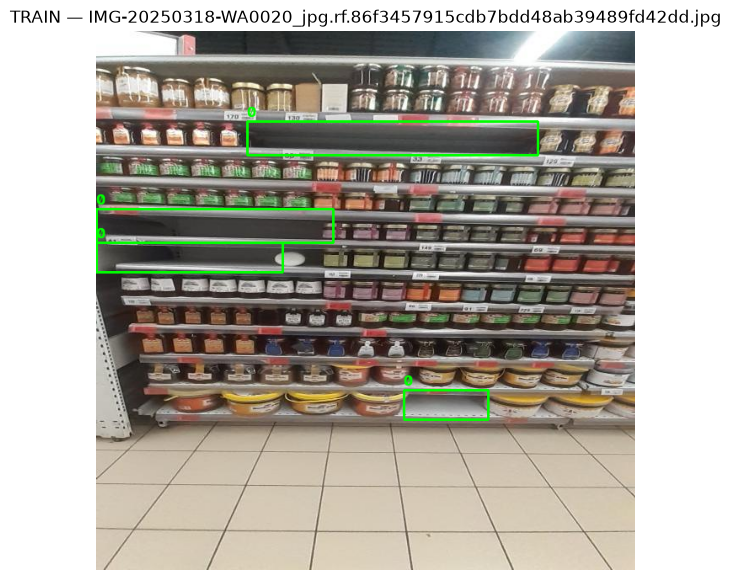

Image: IMG-20250318-WA0020_jpg.rf.86f3457915cdb7bdd48ab39489fd42dd.jpg
Annotation file: Found


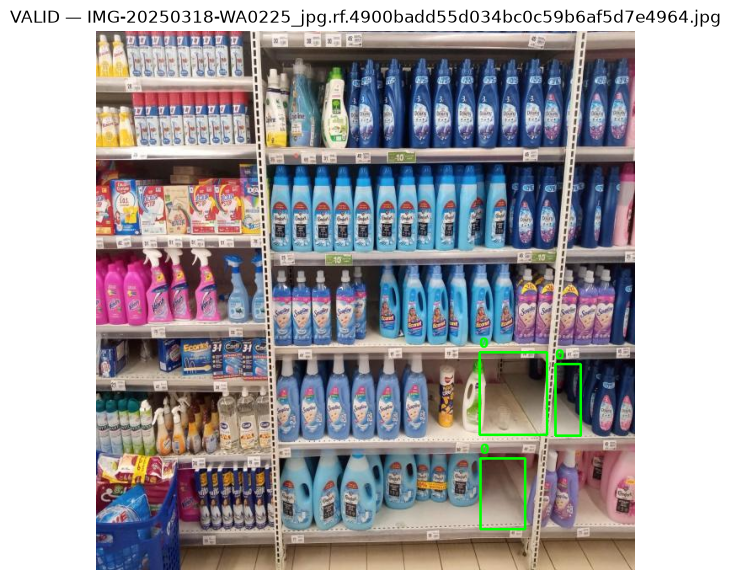

Image: IMG-20250318-WA0225_jpg.rf.4900badd55d034bc0c59b6af5d7e4964.jpg
Annotation file: Found


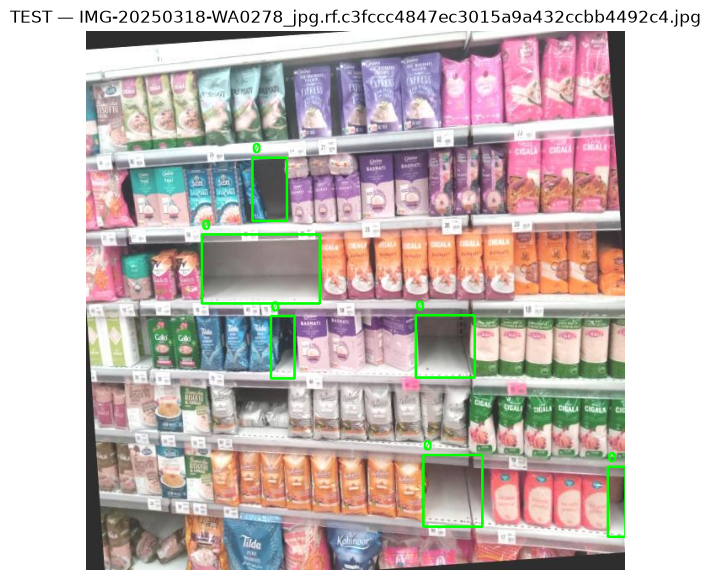

Image: IMG-20250318-WA0278_jpg.rf.c3fccc4847ec3015a9a432ccbb4492c4.jpg
Annotation file: Found


In [4]:
from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt

# Change this if your dataset folder is elsewhere
DATASET_DIR = Path(r"D:\Projects\cv_project\data")

for split in ["train", "valid", "test"]:
    img_dir = DATASET_DIR / split / "images"
    label_dir = DATASET_DIR / split / "labels"

    images = list(img_dir.glob("*"))
    images = [p for p in images if p.suffix.lower() in
              [".jpg", ".jpeg", ".png", ".bmp", ".webp"]]

    if not images:
        print(f"No images found in {split}")
        continue

    # Pick an image that has a matching annotation file
    img_path = random.choice(images)
    label_path = label_dir / f"{img_path.stem}.txt"

    image = cv2.imread(str(img_path))
    if image is None:
        print(f"Could not read: {img_path}")
        continue

    h, w = image.shape[:2]

    # Draw annotations
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = list(map(float, line.split()))
            if len(values) < 5:
                continue

            class_id = int(values[0])
            coords = values[1:]

            # YOLO bounding box: class, x_center, y_center, width, height
            if len(coords) == 4:
                xc, yc, bw, bh = coords
                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)

                cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
                cv2.putText(image, str(class_id), (x1, max(20, y1 - 5)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

            # Polygon annotation: class, x1, y1, x2, y2, ...
            elif len(coords) >= 6 and len(coords) % 2 == 0:
                points = [
                    (int(coords[i] * w), int(coords[i + 1] * h))
                    for i in range(0, len(coords), 2)
                ]
                points = __import__("numpy").array(points, dtype="int32")
                cv2.polylines(image, [points], True, (0, 255, 0), 2)
                cv2.putText(image, str(class_id), tuple(points[0]),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

    # Display image
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(12, 7))
    plt.imshow(image)
    plt.title(f"{split.upper()} — {img_path.name}")
    plt.axis("off")
    plt.show()

    print(f"Image: {img_path.name}")
    print(f"Annotation file: {'Found' if label_path.exists() else 'MISSING'}")